# Exercise 3 - Regularisation: dropout and data augmentation (CIFAR-10)

**PUSL3123 AI and Machine Learning - Assessment 1**

**Aim:** evaluate dropout and data augmentation as regularisers for the Exercise 2 CNN, first independently against the unchanged baseline and then combined as an extension.

**Contents**
1. Setup and configuration
2. Data preparation (standard partitions, validation split, class distribution)
3. Helper functions (training, evaluation, plotting, multi-seed protocol)
4. Models: baseline CNN and dropout variant
5. Data augmentation on the GPU
6. Training: baseline, dropout-rate selection, augmentation ablation, combined run
7. Validation loss curves
8. Final evaluation (main comparison and paired differences)
9. Discussion
10. Save results

**How to run:** `pip install -r requirements.txt`, then *Run All*. Set the environment variable `QUICK_RUN=1` for a 2-epoch smoke test. The dataset downloads automatically into `data/`. The full notebook trains 27 models (9 configurations, 3 seeds each).

## 1. Setup and configuration

All four notebooks share the same configuration (seed, validation size, batch size, learning rate, epochs) so that results are directly comparable.

In [1]:
import os, json, time, random

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision

# ---------------------------------------------------------------------------
# Configuration -- identical in all four notebooks so that results are comparable
# ---------------------------------------------------------------------------
SEED          = 42        # default run seed: weight initialisation, augmentation and batch shuffling
SPLIT_SEED    = 42        # train/validation split: identical for every experiment and every run
SEEDS         = (42, 43, 44)   # run seeds for the multi-seed experiments (Exercises 3 and 4)
VAL_SIZE      = 5_000     # validation images held out from the 50,000 training images
BATCH_SIZE    = 128
LEARNING_RATE = 1e-3
EPOCHS        = 2 if os.environ.get("QUICK_RUN") else 30   # set QUICK_RUN=1 for a 2-epoch smoke test
DATA_DIR      = "data"
RESULTS_DIR   = "results"
FIG_DIR       = os.path.join(RESULTS_DIR, "figures")
DEVICE        = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASSES = ("aeroplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")

os.makedirs(FIG_DIR, exist_ok=True)

def set_seed(seed=SEED):
    """Seed one run: weight initialisation plus dropout and augmentation randomness."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU only")
print(f"Epochs: {EPOCHS} | batch size: {BATCH_SIZE} | learning rate: {LEARNING_RATE} | seed: {SEED}")

PyTorch 2.5.1+cu121 | torchvision 0.20.1+cu121
Device: cuda | NVIDIA GeForce RTX 4050 Laptop GPU
Epochs: 30 | batch size: 128 | learning rate: 0.001 | seed: 42


## 2. Data preparation

* CIFAR-10 is loaded with `torchvision.datasets.CIFAR10` using the **standard partitions**: 50,000 training images and 10,000 test images.
* The test partition is kept completely separate: it is **not** used for training, hyper-parameter tuning or model selection.
* A **validation set of 5,000 images is held out from the 50,000 training images** with a fixed seed (`SPLIT_SEED`), leaving 45,000 images for training. The same split is used in every experiment.
* Images are decoded once into a single `uint8` tensor that lives on `DEVICE` for the rest of the notebook. Each minibatch is normalised with the CIFAR-10 mean and standard deviation on the fly (see `GPULoader` below), which avoids the per-sample CPU transforms and `DataLoader` worker overhead that otherwise dominate training time. Augmentation is introduced in Section 5 and is applied to training batches only; the clean training, validation and test images are never augmented.

In [2]:
# Per-channel mean / std of the CIFAR-10 training images
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
MEAN_T = torch.tensor(MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_T  = torch.tensor(STD,  device=DEVICE).view(1, 3, 1, 1)

class GPULoader:
    """Minibatch iterator over images held entirely on DEVICE as a single uint8 tensor.

    Keeping a whole partition resident on DEVICE and normalising per batch -- instead of per-sample
    disk reads and CPU transforms behind a `DataLoader` -- removes the CPU bottleneck in data loading.
    Shuffling uses a seeded CPU generator so that the epoch order is reproducible; `augment`, if given,
    is applied to the already-normalised batch on the GPU (used from Exercise 3 onwards).
    """
    def __init__(self, images, targets, batch_size, shuffle, seed=SEED, augment=None):
        self.images, self.targets = images, targets   # uint8 (N,3,32,32) / int64 (N,), both on DEVICE
        self.batch_size, self.shuffle, self.augment = batch_size, shuffle, augment
        self.generator = torch.Generator().manual_seed(seed) if shuffle else None

    def __iter__(self):
        n = self.images.size(0)
        order = torch.randperm(n, generator=self.generator) if self.shuffle else torch.arange(n)
        order = order.to(self.images.device)
        for start in range(0, n, self.batch_size):
            idx = order[start:start + self.batch_size]
            x = (self.images[idx].float() / 255 - MEAN_T) / STD_T
            if self.augment is not None:
                x = self.augment(x)
            yield x, self.targets[idx]

    def __len__(self):
        return (self.images.size(0) + self.batch_size - 1) // self.batch_size


_partitions = {}   # decoded tensors, cached so that repeated build_data calls never reload from disk

def load_partitions():
    """Decode CIFAR-10 into DEVICE memory once per kernel and apply the fixed train/validation split.
    Standard partitions (50,000 train / 10,000 test); VAL_SIZE images are held out from the training
    images using SPLIT_SEED, so the split is identical for every experiment and every run seed."""
    if not _partitions:
        train_raw = torchvision.datasets.CIFAR10(DATA_DIR, train=True,  download=True)
        test_raw  = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True)

        def as_device_tensors(ds):
            images = torch.from_numpy(ds.data).permute(0, 3, 1, 2).contiguous().to(DEVICE)  # (N,3,32,32) uint8
            targets = torch.tensor(ds.targets, dtype=torch.long, device=DEVICE)
            return images, targets

        train_images, train_targets = as_device_tensors(train_raw)
        test_images,  test_targets  = as_device_tensors(test_raw)

        perm = torch.randperm(len(train_raw), generator=torch.Generator().manual_seed(SPLIT_SEED))
        val_idx, train_idx = perm[:VAL_SIZE].to(DEVICE), perm[VAL_SIZE:].to(DEVICE)
        _partitions.update(train=(train_images[train_idx], train_targets[train_idx]),
                           val=(train_images[val_idx], train_targets[val_idx]),
                           test=(test_images, test_targets))
    return _partitions


def build_data(augment=None, seed=SEED):
    """Loaders for the fixed partitions. `seed` only controls the shuffling of the training batches (the
    split always uses SPLIT_SEED). `augment` is an optional GPU-side callable applied only to the training
    batches (Exercise 3 onwards). The test set is never used for training or model selection."""
    partitions = load_partitions()

    def loader(name, shuffle=False, augment=None):
        images, targets = partitions[name]
        return GPULoader(images, targets, BATCH_SIZE, shuffle=shuffle, seed=seed, augment=augment)

    return {
        "train":       loader("train", shuffle=True, augment=augment),  # used for training
        "train_clean": loader("train"),                                 # same images, no augmentation
        "val":         loader("val"),                                   # validation (model selection)
        "test":        loader("test"),                                  # final reporting only
    }

loaders = build_data()
print("Images per partition:", {k: v.images.shape[0] for k, v in loaders.items()})

Files already downloaded and verified


Files already downloaded and verified


Images per partition: {'train': 45000, 'train_clean': 45000, 'val': 5000, 'test': 10000}


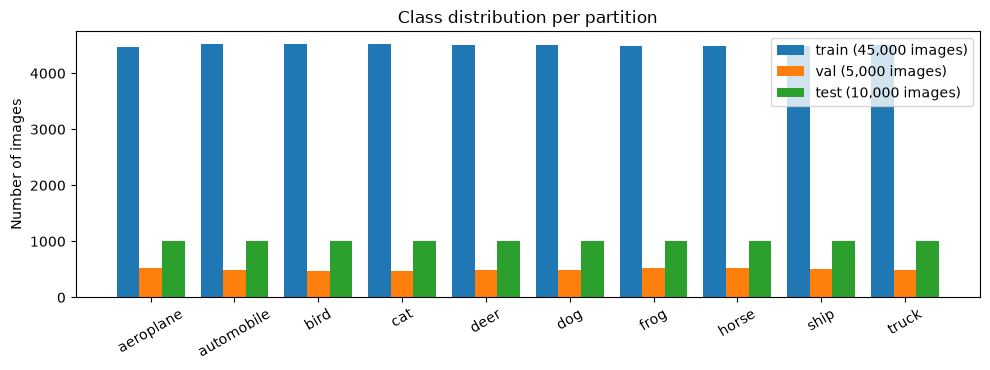

Files already downloaded and verified


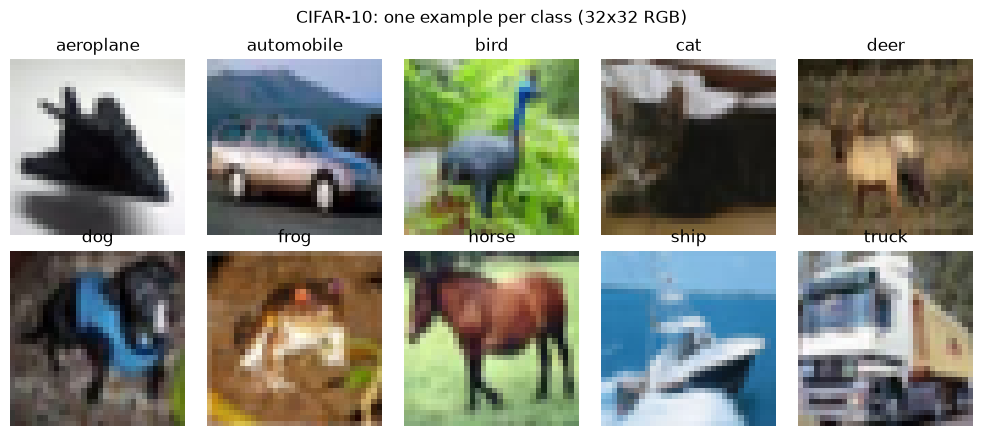

In [3]:
def class_counts(loader):
    """Number of images per class held by a GPULoader partition."""
    return np.bincount(loader.targets.cpu().numpy(), minlength=len(CLASSES))

counts = {name: class_counts(loaders[name]) for name in ("train", "val", "test")}

x, w = np.arange(len(CLASSES)), 0.27
plt.figure(figsize=(10, 3.8))
for i, (name, c) in enumerate(counts.items()):
    plt.bar(x + (i - 1) * w, c, w, label=f"{name} ({c.sum():,} images)")
plt.xticks(x, CLASSES, rotation=30)
plt.ylabel("Number of images")
plt.title("Class distribution per partition")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "class_distribution.png"), dpi=200)
plt.show()

# One example image per class
raw = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
raw_targets = np.array(raw.targets)
fig, axes = plt.subplots(2, 5, figsize=(10, 4.4))
for c, ax in enumerate(axes.ravel()):
    ax.imshow(raw[int(np.where(raw_targets == c)[0][0])][0])
    ax.set_title(CLASSES[c])
    ax.axis("off")
fig.suptitle("CIFAR-10: one example per class (32x32 RGB)")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "cifar10_samples.png"), dpi=200)
plt.show()

## 3. Helper functions

* `fit` trains with **Adam** and **cross-entropy loss**, records loss and accuracy per epoch, and restores the weights of the epoch with the best **validation** accuracy.
* `evaluate` / `final_evaluation` compute loss and accuracy; the test set is only used in `final_evaluation`, after training has finished.
* Plotting and saving utilities produce the figures and JSON results used in the report.

In [4]:
def count_parameters(model):
    """Number of trainable parameters."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, loader):
    """Mean cross-entropy loss and accuracy of `model` on `loader` (eval mode: no dropout)."""
    criterion = nn.CrossEntropyLoss()
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)
        total_loss += criterion(out, y).item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += y.size(0)
    return total_loss / n, correct / n

def fit(model, train_loader, val_loader, epochs=EPOCHS, lr=LEARNING_RATE, weight_decay=0.0, verbose=True):
    """Train with Adam + cross-entropy. After every epoch the model is scored on the validation set; the
    weights of the epoch with the highest validation accuracy are restored at the end (model selection
    uses validation data only -- never the test set). Running loss/accuracy are accumulated as GPU
    tensors and only moved to the CPU once per epoch (`.item()`), instead of after every batch, since a
    host-device sync on every step would otherwise stall the GPU pipeline."""
    criterion = nn.CrossEntropyLoss()
    optimiser = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc, best_epoch, best_state = -1.0, 0, None
    start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        run_loss = torch.zeros((), device=DEVICE)
        run_correct = torch.zeros((), device=DEVICE)
        seen = 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimiser.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimiser.step()
            run_loss += loss.detach() * y.size(0)
            run_correct += (out.argmax(1) == y).sum()
            seen += y.size(0)

        history["train_loss"].append((run_loss / seen).item())
        history["train_acc"].append((run_correct / seen).item())
        val_loss, val_acc = evaluate(model, val_loader)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc, best_epoch = val_acc, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

        if verbose:
            print(f"Epoch {epoch:02d}/{epochs} | train loss {history['train_loss'][-1]:.4f} "
                  f"acc {history['train_acc'][-1]:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}")

    model.load_state_dict(best_state)
    return history, best_epoch, time.time() - start

def final_evaluation(model, loaders):
    """Loss / accuracy on the clean training images, the validation set and the test set."""
    result = {}
    for key, loader_name in (("train", "train_clean"), ("val", "val"), ("test", "test")):
        loss, acc = evaluate(model, loaders[loader_name])
        result[f"{key}_loss"], result[f"{key}_acc"] = loss, acc
    return result

def print_final(final):
    print(f"{'Partition':<12}{'Loss':>8}{'Accuracy':>11}")
    for part in ("train", "val", "test"):
        print(f"{part:<12}{final[part + '_loss']:>8.4f}{final[part + '_acc'] * 100:>10.2f}%")
    gap = (final["train_acc"] - final["test_acc"]) * 100
    print(f"Generalisation gap (train - test accuracy): {gap:.2f} percentage points")

def plot_history(history, best_epoch, title, filename):
    """Training vs validation loss (left) and accuracy (right)."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(epochs, history["train_loss"], label="Training loss")
    axes[0].plot(epochs, history["val_loss"], label="Validation loss")
    axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
    axes[1].plot(epochs, history["train_acc"], label="Training accuracy")
    axes[1].plot(epochs, history["val_acc"], label="Validation accuracy")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy")
    for ax in axes:
        ax.axvline(best_epoch, ls="--", c="grey", label=f"Selected epoch ({best_epoch})")
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, filename), dpi=200)
    plt.show()

@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, labels = [], []
    for x, y in loader:
        preds.append(model(x.to(DEVICE)).argmax(1).cpu())
        labels.append(y.cpu())
    return torch.cat(preds).numpy(), torch.cat(labels).numpy()

def plot_confusion_matrix(model, loader, title, filename):
    """Confusion matrix (rows = true class, columns = predicted class). Returns the count matrix."""
    preds, labels = predict(model, loader)
    cm = np.zeros((len(CLASSES), len(CLASSES)), dtype=int)
    np.add.at(cm, (labels, preds), 1)
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    im = ax.imshow(cm, cmap="Blues")
    ax.set(xticks=range(len(CLASSES)), yticks=range(len(CLASSES)), xlabel="Predicted class",
           ylabel="True class", title=title)
    ax.set_xticklabels(CLASSES, rotation=45, ha="right")
    ax.set_yticklabels(CLASSES)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, filename), dpi=200)
    plt.show()
    return cm

def save_results(name, payload):
    """Write results to results/<name>.json (used for the tables and graphs in the report)."""
    path = os.path.join(RESULTS_DIR, f"{name}.json")
    with open(path, "w") as f:
        json.dump(payload, f, indent=2)
    print("Saved", path)

### Multi-seed protocol

Every configuration is trained from scratch with the run seeds in `SEEDS` (42, 43, 44). The train/validation split never changes (`SPLIT_SEED`); a run seed controls only weight initialisation, dropout and augmentation randomness, and the shuffling of the training batches. Results are reported as **mean ± sample standard deviation** over the three seeds. With only three seeds the standard deviation is itself a rough estimate, so small differences should be read cautiously.

* `run_experiment` trains one model and returns its final metrics, selected epoch, history, training time and parameter count.
* `summarise` gives the mean and standard deviation of every metric over a list of runs.

In [5]:
from IPython.display import Markdown, display

# Chart colours: one fixed categorical order, recessive ink and grid
INK, SECONDARY_INK, MUTED_INK = "#0b0b0b", "#52514e", "#898781"
GRID_COLOUR, AXIS_COLOUR = "#e1e0d9", "#c3c2b7"
SERIES = ("#2a78d6", "#eb6834", "#1baf7a", "#eda100")
LIGHT_BLUE, DARK_BLUE = "#86b6ef", "#184f95"

def run_experiment(make_model, augment=None, seed=SEED, epochs=EPOCHS, lr=LEARNING_RATE, weight_decay=0.0):
    """Train one model from scratch with one run seed and evaluate the selected (best validation) epoch."""
    set_seed(seed)
    model = make_model().to(DEVICE)
    data = build_data(augment=augment, seed=seed)
    history, best_epoch, train_seconds = fit(model, data["train"], data["val"], epochs=epochs, lr=lr,
                                             weight_decay=weight_decay, verbose=False)
    return {
        "seed": seed,
        "final": final_evaluation(model, data),
        "best_epoch": best_epoch,
        "history": history,
        "train_seconds": train_seconds,
        "trainable_parameters": count_parameters(model),
    }

def run_metrics(run):
    """Scalar metrics of one run, including the gaps and the running loss at the selected epoch."""
    final = run["final"]
    return {
        **final,
        "gap": final["train_acc"] - final["test_acc"],            # generalisation gap
        "train_val_gap": final["train_acc"] - final["val_acc"],   # overfitting gap (no test data involved)
        "running_train_loss": run["history"]["train_loss"][run["best_epoch"] - 1],
        "best_epoch": run["best_epoch"],
        "train_seconds": run["train_seconds"],
        "seconds_per_epoch": run["train_seconds"] / len(run["history"]["train_loss"]),
        "trainable_parameters": run["trainable_parameters"],
    }

def summarise(runs):
    """Mean and sample standard deviation (ddof=1) of every metric over a list of runs."""
    rows = [run_metrics(run) for run in runs]
    return {key: {"mean": float(np.mean([row[key] for row in rows])),
                  "std": float(np.std([row[key] for row in rows], ddof=1)) if len(rows) > 1 else 0.0}
            for key in rows[0]}

def run_seeds(name, make_model, augment=None, seeds=SEEDS, **config):
    """Run one configuration once per seed. Progress shows validation accuracy only."""
    runs = []
    for seed in seeds:
        run = run_experiment(make_model, augment=augment, seed=seed)
        run["config"] = {"name": name, **config}
        runs.append(run)
        print(f"{name:<34} seed {seed} | selected epoch {run['best_epoch']:2d} | "
              f"val acc {run['final']['val_acc'] * 100:.2f}% | {run['train_seconds']:.1f} s")
    return runs

def pm(stat, scale=100, digits=2):
    """Format a summary statistic as 'mean ± std'."""
    return f"{stat['mean'] * scale:.{digits}f} ± {stat['std'] * scale:.{digits}f}"

def show_table(headers, rows):
    """Render a table as Markdown in the notebook output."""
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(str(value) for value in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

def curve_stats(runs, key):
    """Per-epoch mean and sample standard deviation of one history curve."""
    curves = np.array([run["history"][key] for run in runs])
    return curves.mean(axis=0), curves.std(axis=0, ddof=1)

def style_axes(ax, grid="y"):
    """Hairline grid behind the marks, no top or right spines, muted ticks."""
    ax.set_axisbelow(True)
    ax.grid(axis=grid, color=GRID_COLOUR, linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS_COLOUR)
    ax.tick_params(colors=SECONDARY_INK, length=3, color=AXIS_COLOUR)


## 4. Models: baseline CNN and dropout variant

The **baseline** is the Exercise 2 CNN class, copied unchanged: two convolutional blocks followed by one linear classifier (60,362 parameters).

**Dropout** adds `nn.Dropout(p)` between `Flatten` and the final `Linear` layer. During training it randomly zeroes a fraction `p` of the 4,096 flattened features, so the classifier cannot rely on any small set of co-adapted features. It is disabled in evaluation mode, and it adds no trainable parameters.

In [6]:
class CNN(nn.Module):
    """Convolutional network with three trainable layers: two convolutional blocks (conv + ReLU +
    max-pool) followed by one fully connected classifier."""
    def __init__(self, num_classes=len(CLASSES)):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),   # trainable layer 1
            nn.ReLU(),
            nn.MaxPool2d(2),                               # 32x32 -> 16x16
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # trainable layer 2
            nn.ReLU(),
            nn.MaxPool2d(2),                               # 16x16 -> 8x8
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, num_classes),           # trainable layer 3 (class scores / logits)
        )

    def forward(self, x):
        return self.net(x)


class CNNDropout(nn.Module):
    """The Exercise 2 CNN with dropout between Flatten and the final Linear layer. Dropout has no weights,
    so the parameter count and the initial weights for a given seed match the baseline."""
    def __init__(self, p, num_classes=len(CLASSES)):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),   # trainable layer 1
            nn.ReLU(),
            nn.MaxPool2d(2),                               # 32x32 -> 16x16
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # trainable layer 2
            nn.ReLU(),
            nn.MaxPool2d(2),                               # 16x16 -> 8x8
            nn.Flatten(),
            nn.Dropout(p),                                 # active in training, disabled in eval mode
            nn.Linear(64 * 8 * 8, num_classes),           # trainable layer 3 (class scores / logits)
        )

    def forward(self, x):
        return self.net(x)

assert count_parameters(CNN()) == 60_362 and count_parameters(CNNDropout(0.5)) == 60_362
print(CNNDropout(0.5))
print(f"\nTrainable parameters (baseline and dropout variants): {count_parameters(CNN()):,}")


CNNDropout(
  (net): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Dropout(p=0.5, inplace=False)
    (8): Linear(in_features=4096, out_features=10, bias=True)
  )
)

Trainable parameters (baseline and dropout variants): 60,362


## 5. Data augmentation on the GPU

Augmentation is implemented with `F.affine_grid` and `F.grid_sample` on the **normalised** batch, with independent random parameters for every image, and is applied to **training batches only**:

* random horizontal flip (p = 0.5);
* random translation of up to +/-4 pixels in each direction (integer shifts);
* random rotation of up to +/-10 degrees.

All active transforms are composed into one affine matrix, so each image is interpolated once. Uncovered areas are filled with 0, which corresponds to the dataset mean colour after normalisation. Flips and integer translations land exactly on pixel centres, which the checks below confirm.

Augmentation checks passed: identity, horizontal flip and integer translation are pixel-exact.


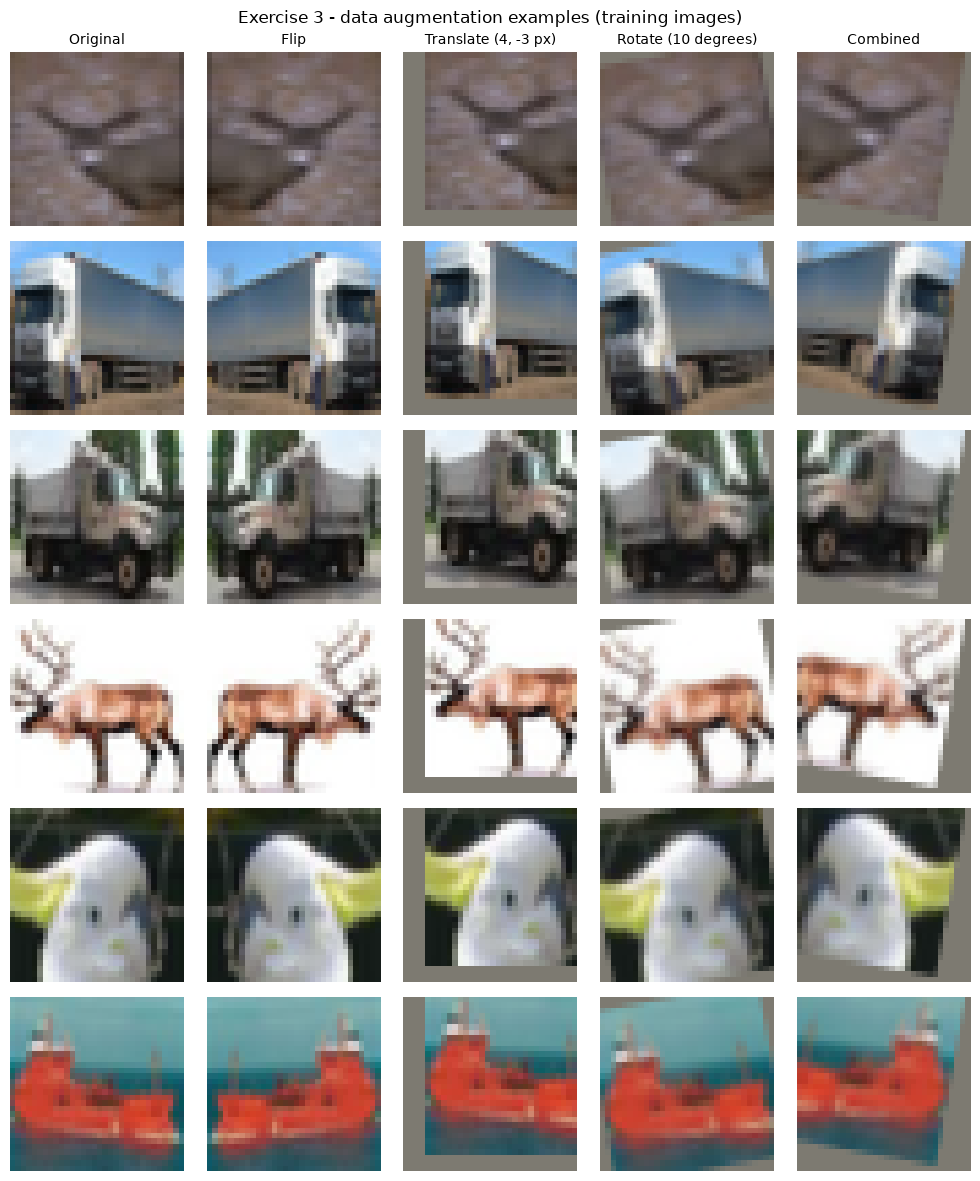

In [7]:
import torch.nn.functional as F

def apply_affine(x, flip, dx, dy, angle_deg):
    """Apply one flip / translation / rotation per image in a single resampling step, so that combined
    transforms are interpolated only once. `dx` and `dy` are in pixels and `angle_deg` in degrees.
    Areas uncovered by the transform are filled with 0, which is the mean colour of the normalised data."""
    _, _, height, width = x.shape
    angle = torch.deg2rad(angle_deg)
    cos, sin = angle.cos(), angle.sin()
    x_scale = 1.0 - 2.0 * flip.float()
    theta = torch.stack([torch.stack([cos * x_scale, -sin, 2 * dx / width], dim=1),
                         torch.stack([sin * x_scale,  cos, 2 * dy / height], dim=1)], dim=1)
    grid = F.affine_grid(theta, x.size(), align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)


class GPUAugment:
    """Random augmentation of a normalised training batch on DEVICE, with independent parameters per image:
    horizontal flip (p=0.5), integer translation up to +/-`translate` pixels, rotation up to +/-`rotate` degrees.
    Randomness comes from the generator seeded by `set_seed`."""
    def __init__(self, flip=False, translate=0, rotate=0.0):
        self.flip, self.translate, self.rotate = flip, translate, rotate

    def __call__(self, x):
        n, device = x.size(0), x.device
        flip = torch.rand(n, device=device) < 0.5 if self.flip else torch.zeros(n, dtype=torch.bool, device=device)
        if self.translate:
            dx = torch.randint(-self.translate, self.translate + 1, (n,), device=device).float()
            dy = torch.randint(-self.translate, self.translate + 1, (n,), device=device).float()
        else:
            dx = dy = torch.zeros(n, device=device)
        angle = (torch.rand(n, device=device) * 2 - 1) * self.rotate if self.rotate else torch.zeros(n, device=device)
        return apply_affine(x, flip, dx, dy, angle)


# Sanity checks: the affine resampling must reproduce exact pixel operations
check = next(iter(loaders["val"]))[0][:8]
none, zero = torch.zeros(8, dtype=torch.bool, device=DEVICE), torch.zeros(8, device=DEVICE)
assert (apply_affine(check, none, zero, zero, zero) - check).abs().max() < 1e-3                       # identity
assert (apply_affine(check, ~none, zero, zero, zero) - check.flip(3)).abs().max() < 1e-3              # flip
assert (apply_affine(check, none, zero + 2, zero, zero)[..., :-2] - check[..., 2:]).abs().max() < 1e-3  # 2 px shift
print("Augmentation checks passed: identity, horizontal flip and integer translation are pixel-exact.")

# Example grid with fixed, clearly visible parameters
n_images = 6
originals = (loaders["train_clean"].images[:n_images].float() / 255 - MEAN_T) / STD_T
no_flip, do_flip = torch.zeros(n_images, dtype=torch.bool, device=DEVICE), torch.ones(n_images, dtype=torch.bool, device=DEVICE)
nil = torch.zeros(n_images, device=DEVICE)
variants = [("Original", originals),
            ("Flip", apply_affine(originals, do_flip, nil, nil, nil)),
            ("Translate (4, -3 px)", apply_affine(originals, no_flip, nil - 4, nil + 3, nil)),
            ("Rotate (10 degrees)", apply_affine(originals, no_flip, nil, nil, nil + 10)),
            ("Combined", apply_affine(originals, do_flip, nil - 4, nil + 3, nil + 10))]

fig, axes = plt.subplots(n_images, len(variants), figsize=(2.0 * len(variants), 2.0 * n_images))
for col, (title, batch) in enumerate(variants):
    shown = (batch * STD_T + MEAN_T).clamp(0, 1).permute(0, 2, 3, 1).cpu().numpy()
    axes[0, col].set_title(title, fontsize=10)
    for row in range(n_images):
        axes[row, col].imshow(shown[row], interpolation="nearest")
        axes[row, col].axis("off")
fig.suptitle("Exercise 3 - data augmentation examples (training images)")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "ex3_augmentation_examples.png"), dpi=200)
plt.show()


## 6. Training

### 6.1 Baseline

The unchanged CNN, trained with the same settings as Exercise 2 (Adam, learning rate 1e-3, batch size 128, 30 epochs, best validation epoch restored). Seed 42 should reproduce the Exercise 2 result.

In [8]:
baseline_runs = run_seeds("Baseline", CNN)
baseline_summary = summarise(baseline_runs)
print(f"\nBaseline validation accuracy: {pm(baseline_summary['val_acc'])}%")


Baseline                           seed 42 | selected epoch 13 | val acc 72.38% | 26.8 s


Baseline                           seed 43 | selected epoch 11 | val acc 72.42% | 25.7 s


Baseline                           seed 44 | selected epoch 12 | val acc 72.48% | 25.8 s

Baseline validation accuracy: 72.43 ± 0.05%


### 6.2 Dropout: rate selection

Three rates are compared, each with three seeds. The rate is chosen by **mean validation accuracy**; the test set is not consulted. The validation accuracy of the chosen rate is slightly optimistic because the same data was used to choose it.

Dropout p=0.25                     seed 42 | selected epoch 30 | val acc 75.42% | 26.1 s


Dropout p=0.25                     seed 43 | selected epoch 28 | val acc 75.36% | 26.2 s


Dropout p=0.25                     seed 44 | selected epoch 20 | val acc 75.04% | 26.2 s


Dropout p=0.5                      seed 42 | selected epoch 25 | val acc 76.32% | 26.1 s


Dropout p=0.5                      seed 43 | selected epoch 27 | val acc 76.14% | 26.2 s


Dropout p=0.5                      seed 44 | selected epoch 29 | val acc 76.50% | 26.2 s


Dropout p=0.75                     seed 42 | selected epoch 30 | val acc 76.04% | 26.1 s


Dropout p=0.75                     seed 43 | selected epoch 26 | val acc 75.68% | 26.2 s


Dropout p=0.75                     seed 44 | selected epoch 29 | val acc 75.66% | 26.1 s


| Dropout rate | Validation accuracy (%) | Selected epoch | Chosen |
|---|---|---|---|
| 0.25 | 75.27 ± 0.20 | 26.0 ± 5.3 |  |
| 0.5 | 76.32 ± 0.18 | 27.0 ± 2.0 | yes |
| 0.75 | 75.79 ± 0.21 | 28.3 ± 2.1 |  |

Chosen dropout rate: p = 0.5


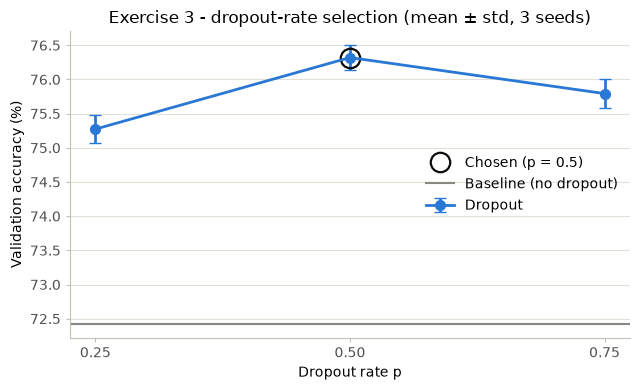

In [9]:
DROPOUT_RATES = (0.25, 0.5, 0.75)
dropout_runs = {p: run_seeds(f"Dropout p={p}", lambda p=p: CNNDropout(p), dropout=p) for p in DROPOUT_RATES}
dropout_summary = {p: summarise(runs) for p, runs in dropout_runs.items()}

# The rate is chosen on mean validation accuracy only; test accuracy plays no part
chosen_p = max(DROPOUT_RATES, key=lambda p: dropout_summary[p]["val_acc"]["mean"])
show_table(["Dropout rate", "Validation accuracy (%)", "Selected epoch", "Chosen"],
           [[p, pm(dropout_summary[p]["val_acc"]), pm(dropout_summary[p]["best_epoch"], 1, 1),
             "yes" if p == chosen_p else ""] for p in DROPOUT_RATES])
print(f"Chosen dropout rate: p = {chosen_p}")

fig, ax = plt.subplots(figsize=(6.5, 4))
means = [dropout_summary[p]["val_acc"]["mean"] * 100 for p in DROPOUT_RATES]
stds = [dropout_summary[p]["val_acc"]["std"] * 100 for p in DROPOUT_RATES]
ax.errorbar(DROPOUT_RATES, means, yerr=stds, marker="o", ms=7, lw=2, capsize=4, color=SERIES[0], label="Dropout")
ax.plot(chosen_p, means[DROPOUT_RATES.index(chosen_p)], "o", ms=14, mfc="none", mec=INK, mew=1.6,
        label=f"Chosen (p = {chosen_p})")
ax.axhline(baseline_summary["val_acc"]["mean"] * 100, color=MUTED_INK, lw=1.5, label="Baseline (no dropout)")
ax.set(xlabel="Dropout rate p", ylabel="Validation accuracy (%)", xticks=DROPOUT_RATES,
       title="Exercise 3 - dropout-rate selection (mean ± std, 3 seeds)")
style_axes(ax)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "ex3_dropout_rate_selection.png"), dpi=200)
plt.show()


### 6.3 Data augmentation: ablation

Each transform is evaluated alone against the unchanged baseline, followed by all three together. The all-three variant was fixed in advance as the main "augmentation" method, so the ablation is not used to select it.

Flip only                          seed 42 | selected epoch 22 | val acc 75.60% | 28.9 s


Flip only                          seed 43 | selected epoch 15 | val acc 74.84% | 28.8 s


Flip only                          seed 44 | selected epoch 20 | val acc 75.82% | 28.9 s


Translation only                   seed 42 | selected epoch 30 | val acc 77.46% | 29.0 s


Translation only                   seed 43 | selected epoch 29 | val acc 76.86% | 28.9 s


Translation only                   seed 44 | selected epoch 25 | val acc 77.12% | 29.0 s


... (3 outputs left out)

Augmentation (all three)           seed 42 | selected epoch 30 | val acc 77.26% | 29.3 s


Augmentation (all three)           seed 43 | selected epoch 28 | val acc 76.14% | 29.2 s


Augmentation (all three)           seed 44 | selected epoch 28 | val acc 75.94% | 29.3 s


| Variant | Train acc (%) | Val acc (%) | Test acc (%) | Gap (pts) | Test change vs baseline (pts) |
|---|---|---|---|---|---|
| Baseline | 85.87 ± 1.15 | 72.43 ± 0.05 | 71.24 ± 0.06 | 14.63 ± 1.10 | - |
| Flip only | 84.01 ± 2.16 | 75.42 ± 0.51 | 74.12 ± 0.74 | 9.88 ± 1.59 | 2.88 ± 0.68 |
| Translation only | 81.06 ± 0.48 | 77.15 ± 0.30 | 76.28 ± 0.42 | 4.79 ± 0.09 | 5.03 ± 0.43 |
| Rotation only | 85.05 ± 1.51 | 74.15 ± 0.61 | 72.95 ± 0.26 | 12.09 ± 1.45 | 1.71 ± 0.19 |
| Augmentation (all three) | 77.60 ± 0.51 | 76.45 ± 0.71 | 75.59 ± 0.68 | 2.01 ± 0.33 | 4.34 ± 0.65 |

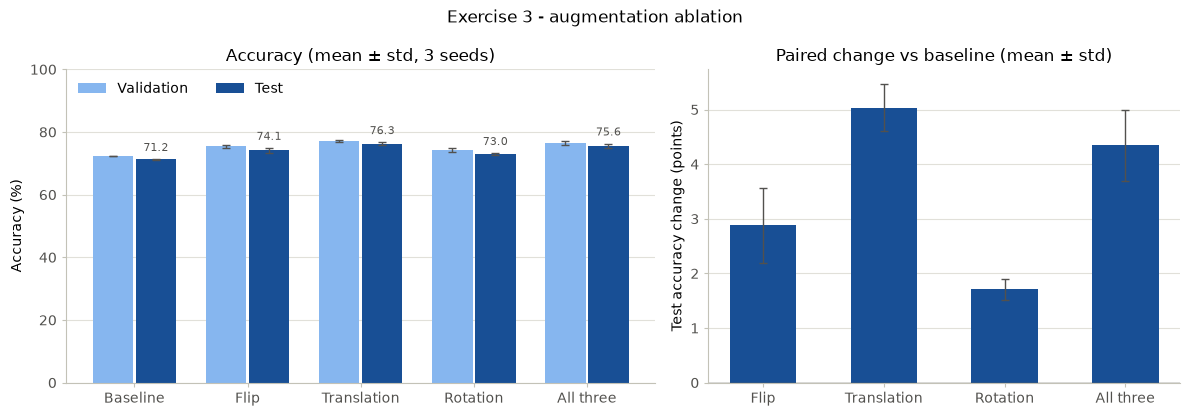

In [10]:
def paired_difference(runs, reference, metric):
    """Per-seed difference (runs - reference) for one metric, with its mean and sample std over seeds."""
    other = {run["seed"]: run_metrics(run)[metric] for run in runs}
    base = {run["seed"]: run_metrics(run)[metric] for run in reference}
    diffs = [other[seed] - base[seed] for seed in sorted(base)]
    return {"mean": float(np.mean(diffs)), "std": float(np.std(diffs, ddof=1)) if len(diffs) > 1 else 0.0,
            "per_seed": diffs}

AUGMENTATIONS = {"Flip only": {"flip": True},
                 "Translation only": {"translate": 4},
                 "Rotation only": {"rotate": 10.0},
                 "Augmentation (all three)": {"flip": True, "translate": 4, "rotate": 10.0}}
aug_runs = {name: run_seeds(name, CNN, augment=GPUAugment(**kw), **kw) for name, kw in AUGMENTATIONS.items()}
aug_summary = {name: summarise(runs) for name, runs in aug_runs.items()}

ablation = {"Baseline": baseline_runs, **aug_runs}
show_table(["Variant", "Train acc (%)", "Val acc (%)", "Test acc (%)", "Gap (pts)", "Test change vs baseline (pts)"],
           [[name, pm(summarise(runs)["train_acc"]), pm(summarise(runs)["val_acc"]), pm(summarise(runs)["test_acc"]),
             pm(summarise(runs)["gap"]),
             "-" if name == "Baseline" else pm(paired_difference(runs, baseline_runs, "test_acc"))]
            for name, runs in ablation.items()])

short = ["Baseline", "Flip", "Translation", "Rotation", "All three"]
pos, width = np.arange(len(short)), 0.38
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
for offset, metric, label, colour in ((-width / 2, "val_acc", "Validation", LIGHT_BLUE), (width / 2, "test_acc", "Test", DARK_BLUE)):
    stats = [summarise(runs)[metric] for runs in ablation.values()]
    bars = axes[0].bar(pos + offset, [s["mean"] * 100 for s in stats], width * 0.94, yerr=[s["std"] * 100 for s in stats],
                       color=colour, label=label, capsize=3, error_kw={"elinewidth": 1, "ecolor": SECONDARY_INK})
    if metric == "test_acc":
        axes[0].bar_label(bars, fmt="%.1f", padding=4, fontsize=8, color=SECONDARY_INK)
axes[0].set(xticks=pos, xticklabels=short, ylabel="Accuracy (%)", ylim=(0, 100), title="Accuracy (mean ± std, 3 seeds)")
axes[0].legend(frameon=False, loc="upper left", ncol=2)
style_axes(axes[0])

changes = [paired_difference(runs, baseline_runs, "test_acc") for runs in aug_runs.values()]
axes[1].bar(pos[:-1], [c["mean"] * 100 for c in changes], 0.55, yerr=[c["std"] * 100 for c in changes], color=DARK_BLUE,
            capsize=3, error_kw={"elinewidth": 1, "ecolor": SECONDARY_INK})
axes[1].axhline(0, color=SECONDARY_INK, lw=1)
axes[1].set(xticks=pos[:-1], xticklabels=short[1:], ylabel="Test accuracy change (points)",
            title="Paired change vs baseline (mean ± std)")
style_axes(axes[1])
fig.suptitle("Exercise 3 - augmentation ablation")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "ex3_augmentation_ablation.png"), dpi=200)
plt.show()


### 6.4 Combined run (extension)

The chosen dropout rate together with all three augmentations.

In [11]:
combined_name = f"Combined (p={chosen_p} + augmentation)"
combined_runs = run_seeds(combined_name, lambda: CNNDropout(chosen_p),
                          augment=GPUAugment(flip=True, translate=4, rotate=10.0),
                          dropout=chosen_p, flip=True, translate=4, rotate=10.0)

# The four main methods; the dropout runs are those of the chosen rate from the selection above
methods = {"Baseline": baseline_runs,
           f"Dropout (p={chosen_p})": dropout_runs[chosen_p],
           "Augmentation": aug_runs["Augmentation (all three)"],
           "Combined": combined_runs}
main_summary = {name: summarise(runs) for name, runs in methods.items()}


Combined (p=0.5 + augmentation)    seed 42 | selected epoch 28 | val acc 74.98% | 29.5 s


Combined (p=0.5 + augmentation)    seed 43 | selected epoch 30 | val acc 73.88% | 29.4 s


Combined (p=0.5 + augmentation)    seed 44 | selected epoch 30 | val acc 74.66% | 29.5 s


## 7. Validation loss curves

Mean validation loss per epoch, with a band of one standard deviation over the seeds.

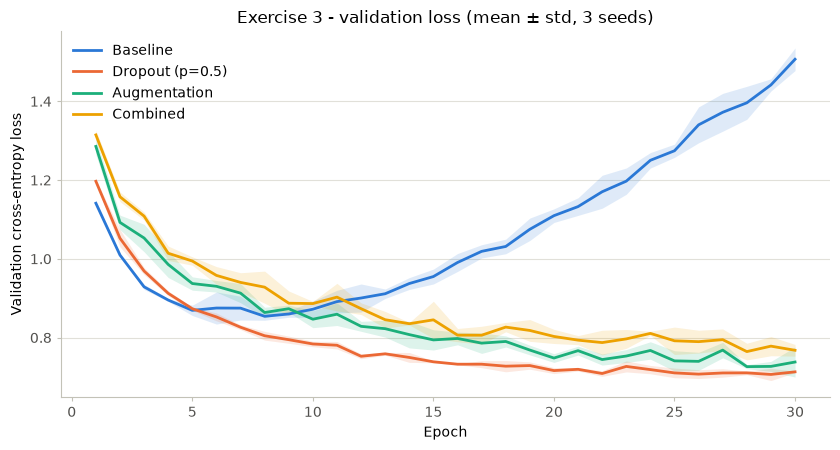

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for colour, (name, runs) in zip(SERIES, methods.items()):
    mean, std = curve_stats(runs, "val_loss")
    epochs = np.arange(1, len(mean) + 1)
    ax.plot(epochs, mean, color=colour, lw=2, label=name)
    ax.fill_between(epochs, mean - std, mean + std, color=colour, alpha=0.15, linewidth=0)
ax.set(xlabel="Epoch", ylabel="Validation cross-entropy loss",
       title="Exercise 3 - validation loss (mean ± std, 3 seeds)")
style_axes(ax)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "ex3_val_loss_curves.png"), dpi=200)
plt.show()


## 8. Final evaluation

For every run, the weights of the best validation epoch are evaluated once on the clean training images (evaluation mode), the validation set and the test set. The **generalisation gap** is train accuracy minus test accuracy. Paired differences compare each method with the baseline run that used the same seed.

| Method | Train acc (%) | Val acc (%) | Test acc (%) | Gap (pts) | Selected epoch | Time (s) | Parameters |
|---|---|---|---|---|---|---|---|
| Baseline | 85.87 ± 1.15 | 72.43 ± 0.05 | 71.24 ± 0.06 | 14.63 ± 1.10 | 12.0 ± 1.0 | 26.1 ± 0.6 | 60,362 |
| Dropout (p=0.5) | 85.65 ± 0.56 | 76.32 ± 0.18 | 75.40 ± 0.30 | 10.25 ± 0.48 | 27.0 ± 2.0 | 26.2 ± 0.0 | 60,362 |
| Augmentation | 77.60 ± 0.51 | 76.45 ± 0.71 | 75.59 ± 0.68 | 2.01 ± 0.33 | 28.7 ± 1.2 | 29.3 ± 0.0 | 60,362 |
| Combined | 75.06 ± 0.53 | 74.51 ± 0.57 | 73.67 ± 0.80 | 1.39 ± 0.27 | 29.3 ± 1.2 | 29.5 ± 0.0 | 60,362 |

| Method | Test acc change (pts) | Beyond 1 std? | Gap change (pts) | Beyond 1 std? |
|---|---|---|---|---|
| Dropout (p=0.5) | 4.16 ± 0.24 | yes | -4.39 ± 1.57 | yes |
| Augmentation | 4.34 ± 0.65 | yes | -12.62 ± 1.33 | yes |
| Combined | 2.43 ± 0.74 | yes | -13.24 ± 1.32 | yes |

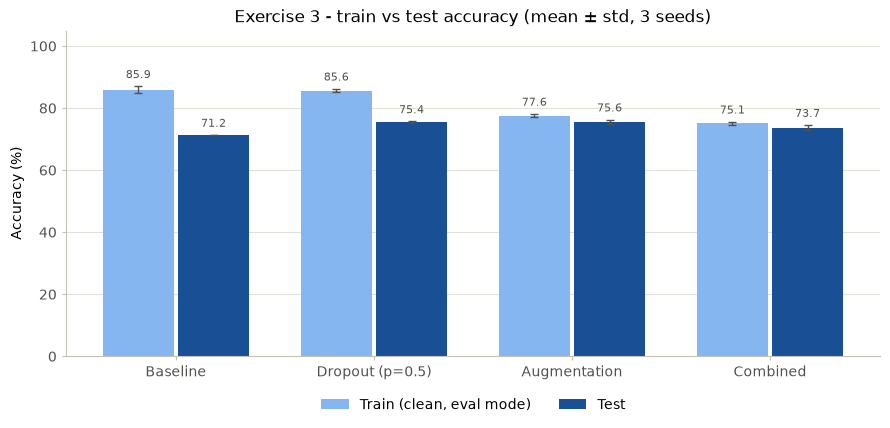

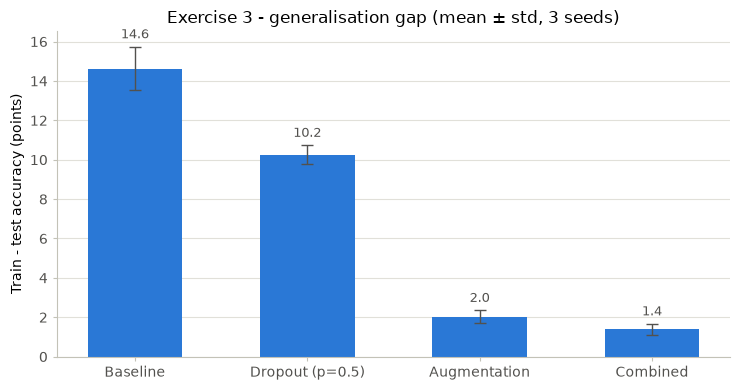

In [13]:
show_table(["Method", "Train acc (%)", "Val acc (%)", "Test acc (%)", "Gap (pts)", "Selected epoch", "Time (s)", "Parameters"],
           [[name, pm(s["train_acc"]), pm(s["val_acc"]), pm(s["test_acc"]), pm(s["gap"]), pm(s["best_epoch"], 1, 1),
             pm(s["train_seconds"], 1, 1), f"{int(s['trainable_parameters']['mean']):,}"]
            for name, s in main_summary.items()])

# Paired differences against the baseline: the same seed gives the same split, initial weights and batch order
paired = {name: {metric: paired_difference(runs, baseline_runs, metric) for metric in ("test_acc", "gap")}
          for name, runs in methods.items() if name != "Baseline"}

def exceeds_one_std(diff):
    """True when the mean paired change is larger in size than the std of the changes."""
    return abs(diff["mean"]) > diff["std"]

show_table(["Method", "Test acc change (pts)", "Beyond 1 std?", "Gap change (pts)", "Beyond 1 std?"],
           [[name, pm(d["test_acc"]), "yes" if exceeds_one_std(d["test_acc"]) else "no",
             pm(d["gap"]), "yes" if exceeds_one_std(d["gap"]) else "no"] for name, d in paired.items()])

names, pos, width = list(main_summary), np.arange(len(main_summary)), 0.38
fig, ax = plt.subplots(figsize=(9, 4.4))
for offset, metric, label, colour in ((-width / 2, "train_acc", "Train (clean, eval mode)", LIGHT_BLUE),
                                      (width / 2, "test_acc", "Test", DARK_BLUE)):
    bars = ax.bar(pos + offset, [main_summary[n][metric]["mean"] * 100 for n in names], width * 0.94,
                  yerr=[main_summary[n][metric]["std"] * 100 for n in names], color=colour, label=label,
                  capsize=3, error_kw={"elinewidth": 1, "ecolor": SECONDARY_INK})
    ax.bar_label(bars, fmt="%.1f", padding=4, fontsize=8, color=SECONDARY_INK)
ax.set(xticks=pos, xticklabels=names, ylabel="Accuracy (%)", ylim=(0, 105),
       title="Exercise 3 - train vs test accuracy (mean ± std, 3 seeds)")
style_axes(ax)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "ex3_comparison_accuracy.png"), dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4))
bars = ax.bar(pos, [main_summary[n]["gap"]["mean"] * 100 for n in names], 0.55,
              yerr=[main_summary[n]["gap"]["std"] * 100 for n in names], color=SERIES[0], capsize=4,
              error_kw={"elinewidth": 1, "ecolor": SECONDARY_INK})
ax.bar_label(bars, fmt="%.1f", padding=4, fontsize=9, color=SECONDARY_INK)
ax.set(xticks=pos, xticklabels=names, ylabel="Train - test accuracy (points)",
       title="Exercise 3 - generalisation gap (mean ± std, 3 seeds)")
style_axes(ax)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "ex3_generalisation_gap.png"), dpi=200)
plt.show()


## 9. Discussion

Figures are mean ± std over three seeds. Changes are paired with the baseline run of the same seed.

**Techniques that help**

* **Dropout (p = 0.5)** raises test accuracy from 71.24% to 75.40% (+4.16 ± 0.24 points) and narrows the generalisation gap from 14.63 to 10.25 points (-4.39 ± 1.57). The rate was chosen on validation accuracy: 76.32% for p = 0.5, against 75.27% for 0.25 and 75.79% for 0.75.
* **Augmentation (all three)** raises test accuracy to 75.59% (+4.34 ± 0.65 points) and gives a much smaller gap of 2.01 points (-12.62 ± 1.33). About 8.3 points of that reduction come from lower training accuracy and about 4.3 from higher test accuracy, so a smaller gap is not in itself the same as better performance.
* The validation loss curves show the same pattern: the baseline loss starts rising after roughly epoch 8, while the regularised models keep improving or level off.

**Differences that should not be overclaimed**

* Dropout and augmentation **cannot be ranked on accuracy**: augmentation is ahead by only 0.18 ± 0.69 test points, which is within one standard deviation. Augmentation does clearly produce the smaller gap.

**Augmentation ablation**

* **Translation** gives the largest single benefit (+5.03 ± 0.43 test points), followed by **flip** (+2.88 ± 0.68). **Rotation** has the most limited benefit (+1.71 ± 0.19), and its gap reduction (-2.54 ± 2.31) is barely larger than its spread.
* A likely reason is that CIFAR-10 objects vary in position and left-right orientation but are usually upright, and rotation also adds interpolation blur and filled corners. This experiment does not test that explanation directly.
* Translation alone scored 0.69 ± 0.45 test points above all three together (0.70 ± 0.49 on validation), so adding transforms did not automatically help. The all-three variant remains the main method because it was fixed in advance, not chosen after seeing these results.

**Combined run**

* Combining dropout and augmentation still beats the baseline (+2.43 ± 0.74 test points) and has the smallest gap (1.39 points), but it is **worse than either technique alone**: 1.92 ± 0.57 points below augmentation and 1.73 ± 0.58 below dropout. Its training accuracy falls to 75.06%, which suggests that this small 60,362-parameter network is over-regularised, and possibly under-trained, when both are applied.

**Limitations**

* The dropout, augmentation and combined runs selected epochs 27 to 29 on average out of 30, so they may still have been improving. The ranking applies to this 30-epoch budget, and the combined run could gain the most from longer training.
* Three seeds give only a rough estimate of the spread. The seeds vary initialisation, dropout, augmentation and batch order, but not the data split or test set, so the reported std excludes test-sampling uncertainty (about ±0.4 points, one standard error, for 10,000 images at 75% accuracy).
* The validation accuracy of the chosen dropout rate is slightly optimistic because it was used for the choice. The test set was not used for any selection.

## 10. Save results

`results/ex3_regularisation.json` stores every individual run (configuration, seed, metrics and history) and the aggregated summaries used in the report.

In [14]:
all_runs = baseline_runs + [run for runs in dropout_runs.values() for run in runs] \
           + [run for runs in aug_runs.values() for run in runs] + combined_runs
save_results("ex3_regularisation", {
    "experiment": "Exercise 3 - Regularisation",
    "config": {"seeds": list(SEEDS), "split_seed": SPLIT_SEED, "val_size": VAL_SIZE, "batch_size": BATCH_SIZE,
               "epochs": EPOCHS, "learning_rate": LEARNING_RATE, "optimiser": "Adam", "loss": "CrossEntropyLoss"},
    "device": str(DEVICE),
    "std": "sample standard deviation (ddof=1) over seeds",
    "chosen_dropout": chosen_p,
    "dropout_selection": {str(p): dropout_summary[p] for p in DROPOUT_RATES},
    "augmentation_ablation": {name: summarise(runs) for name, runs in ablation.items()},
    "summary": main_summary,
    "paired_vs_baseline": paired,
    "runs": [{"config": r["config"], "seed": r["seed"], "metrics": run_metrics(r), "final": r["final"],
              "best_epoch": r["best_epoch"], "train_seconds": r["train_seconds"],
              "trainable_parameters": r["trainable_parameters"], "history": r["history"]} for r in all_runs],
})
print("Individual runs saved:", len(all_runs))


Saved results\ex3_regularisation.json
Individual runs saved: 27


---

## 11. EXTENSION (outside the main protocol): longer training (60 epochs)

**This section is an extension. The main results of this exercise are the 30-epoch results in Sections 6 to 10, and nothing in those sections depends on this one.**

The main discussion noted that the regularised runs selected epochs close to the 30-epoch limit, so they may still have been improving. This extension re-runs the four main methods (baseline, dropout at the chosen rate, augmentation with all three transforms, and combined) for **60 epochs** with the same three seeds. Everything else is identical: the same split, Adam, learning rate 1e-3, batch size 128 and the best-validation-epoch rule. The test set is reported only and is not used for any choice.

### 11.1 Training

In [15]:
# EXTENSION ONLY: the main protocol in Sections 1-10 stays at EPOCHS (30 epochs)
EXT_EPOCHS = 2 if os.environ.get("QUICK_RUN") else 60
EXT_AUGMENT = {"flip": True, "translate": 4, "rotate": 10.0}
ext_dropout = f"Dropout (p={chosen_p})"
ext_methods = {
    "Baseline":     (CNN, None, {"dropout": None}),
    ext_dropout:    (lambda: CNNDropout(chosen_p), None, {"dropout": chosen_p}),
    "Augmentation": (CNN, GPUAugment(**EXT_AUGMENT), {"dropout": None, **EXT_AUGMENT}),
    "Combined":     (lambda: CNNDropout(chosen_p), GPUAugment(**EXT_AUGMENT), {"dropout": chosen_p, **EXT_AUGMENT}),
}

ext_runs = {}
for name, (make_model, augment, settings) in ext_methods.items():
    ext_runs[name] = []
    for seed in SEEDS:
        run = run_experiment(make_model, augment=augment, seed=seed, epochs=EXT_EPOCHS)
        run["config"] = {"name": name, "epochs": EXT_EPOCHS, **settings}
        ext_runs[name].append(run)
        print(f"{name:<18} seed {seed} | selected epoch {run['best_epoch']:2d} | "
              f"val acc {run['final']['val_acc'] * 100:.2f}% | {run['train_seconds']:.1f} s")

# The same seed follows the same training path, so the first EPOCHS epochs should equal the main run
ext_prefix_match = {name: all(run["history"][key][:EPOCHS] == main["history"][key]
                              for run, main in zip(runs, methods[name]) for key in run["history"])
                    for name, runs in ext_runs.items()}
print(f"\nFirst {EPOCHS} epochs identical to the main runs:", ext_prefix_match)


Baseline           seed 42 | selected epoch 13 | val acc 72.38% | 51.5 s


Baseline           seed 43 | selected epoch 11 | val acc 72.42% | 51.5 s


Baseline           seed 44 | selected epoch 12 | val acc 72.48% | 51.5 s


Dropout (p=0.5)    seed 42 | selected epoch 49 | val acc 77.68% | 52.3 s


Dropout (p=0.5)    seed 43 | selected epoch 38 | val acc 76.98% | 52.3 s


Dropout (p=0.5)    seed 44 | selected epoch 52 | val acc 77.20% | 52.3 s


... (2 outputs left out)

Augmentation       seed 44 | selected epoch 60 | val acc 77.72% | 58.4 s


Combined           seed 42 | selected epoch 52 | val acc 77.46% | 58.9 s


Combined           seed 43 | selected epoch 56 | val acc 76.56% | 58.7 s


Combined           seed 44 | selected epoch 58 | val acc 77.68% | 58.9 s

First 30 epochs identical to the main runs: {'Baseline': True, 'Dropout (p=0.5)': True, 'Augmentation': True, 'Combined': True}


### 11.2 Results

In [16]:
ext_summary = {name: summarise(runs) for name, runs in ext_runs.items()}
show_table(["Method (60 epochs)", "Train acc (%)", "Val acc (%)", "Test acc (%)", "Gap (pts)", "Selected epoch", "Time (s)"],
           [[name, pm(s["train_acc"]), pm(s["val_acc"]), pm(s["test_acc"]), pm(s["gap"]), pm(s["best_epoch"], 1, 1),
             pm(s["train_seconds"], 1, 1)] for name, s in ext_summary.items()])

# Effect of the longer budget: each 60-epoch run minus the 30-epoch run with the same seed
ext_vs_main = {name: {metric: paired_difference(runs, methods[name], metric) for metric in ("val_acc", "test_acc", "gap")}
               for name, runs in ext_runs.items()}
show_table(["Change from 30 to 60 epochs", "Val acc (pts)", "Test acc (pts)", "Gap (pts)"],
           [[name, pm(d["val_acc"]), pm(d["test_acc"]), pm(d["gap"])] for name, d in ext_vs_main.items()])

# Ranking check: the same paired comparisons at both training lengths
ext_pairs = (("Combined", ext_dropout), ("Combined", "Augmentation"), ("Augmentation", ext_dropout),
             (ext_dropout, "Baseline"), ("Augmentation", "Baseline"), ("Combined", "Baseline"))

def ext_pairwise(runs_by_method):
    """Paired differences (first - second) in validation and test accuracy for each pair of methods."""
    return {f"{a} - {b}": {metric: paired_difference(runs_by_method[a], runs_by_method[b], metric)
                           for metric in ("val_acc", "test_acc")} for a, b in ext_pairs}

def flagged(diff):
    """Format a paired difference, marking it when its mean is larger than one standard deviation."""
    return pm(diff) + (" *" if exceeds_one_std(diff) else "")

ext_pairwise_30, ext_pairwise_60 = ext_pairwise(methods), ext_pairwise(ext_runs)
show_table(["Comparison (points)", "Val, 30 epochs", "Val, 60 epochs", "Test, 30 epochs", "Test, 60 epochs"],
           [[pair, flagged(ext_pairwise_30[pair]["val_acc"]), flagged(ext_pairwise_60[pair]["val_acc"]),
             flagged(ext_pairwise_30[pair]["test_acc"]), flagged(ext_pairwise_60[pair]["test_acc"])]
            for pair in ext_pairwise_60])
print("* the mean paired difference is larger than one standard deviation of the differences")


| Method (60 epochs) | Train acc (%) | Val acc (%) | Test acc (%) | Gap (pts) | Selected epoch | Time (s) |
|---|---|---|---|---|---|---|
| Baseline | 85.87 ± 1.15 | 72.43 ± 0.05 | 71.24 ± 0.06 | 14.63 ± 1.10 | 12.0 ± 1.0 | 51.5 ± 0.0 |
| Dropout (p=0.5) | 88.78 ± 1.19 | 77.29 ± 0.36 | 76.37 ± 0.81 | 12.40 ± 0.64 | 46.3 ± 7.4 | 52.3 ± 0.0 |
| Augmentation | 80.37 ± 0.27 | 78.38 ± 0.58 | 77.95 ± 0.16 | 2.42 ± 0.25 | 54.3 ± 5.1 | 58.4 ± 0.1 |
| Combined | 77.84 ± 0.29 | 77.23 ± 0.59 | 76.02 ± 0.33 | 1.81 ± 0.04 | 55.3 ± 3.1 | 58.8 ± 0.1 |

| Change from 30 to 60 epochs | Val acc (pts) | Test acc (pts) | Gap (pts) |
|---|---|---|---|
| Baseline | 0.00 ± 0.00 | 0.00 ± 0.00 | 0.00 ± 0.00 |
| Dropout (p=0.5) | 0.97 ± 0.35 | 0.97 ± 0.53 | 2.16 ± 0.38 |
| Augmentation | 1.93 ± 0.49 | 2.36 ± 0.75 | 0.41 ± 0.53 |
| Combined | 2.73 ± 0.27 | 2.35 ± 0.54 | 0.43 ± 0.24 |

| Comparison (points) | Val, 30 epochs | Val, 60 epochs | Test, 30 epochs | Test, 60 epochs |
|---|---|---|---|---|
| Combined - Dropout (p=0.5) | -1.81 ± 0.46 * | -0.05 ± 0.47 | -1.73 ± 0.58 * | -0.35 ± 0.49 |
| Combined - Augmentation | -1.94 ± 0.57 * | -1.15 ± 1.02 * | -1.92 ± 0.57 * | -1.93 ± 0.22 * |
| Augmentation - Dropout (p=0.5) | 0.13 ± 0.76 | 1.09 ± 0.56 * | 0.18 ± 0.69 | 1.58 ± 0.71 * |
| Dropout (p=0.5) - Baseline | 3.89 ± 0.16 * | 4.86 ± 0.39 * | 4.16 ± 0.24 * | 5.13 ± 0.74 * |
| Augmentation - Baseline | 4.02 ± 0.76 * | 5.95 ± 0.63 * | 4.34 ± 0.65 * | 6.71 ± 0.13 * |
| Combined - Baseline | 2.08 ± 0.58 * | 4.81 ± 0.58 * | 2.43 ± 0.74 * | 4.78 ± 0.27 * |

* the mean paired difference is larger than one standard deviation of the differences


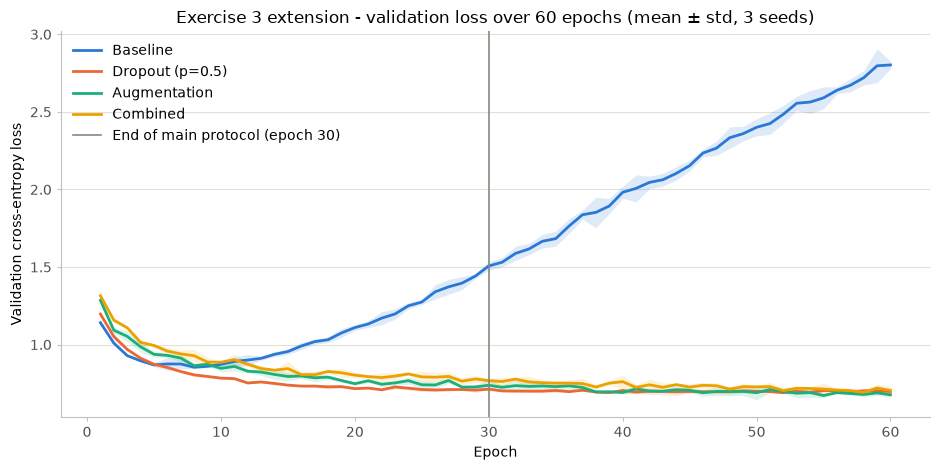

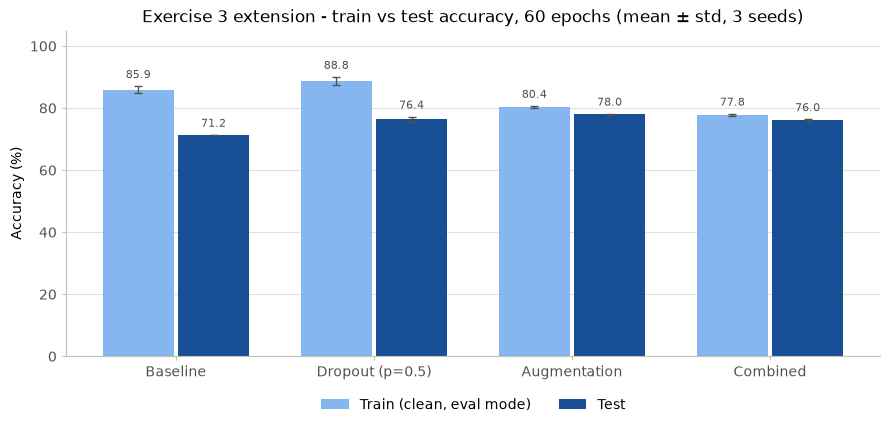

In [17]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for colour, (name, runs) in zip(SERIES, ext_runs.items()):
    mean, std = curve_stats(runs, "val_loss")
    epochs = np.arange(1, len(mean) + 1)
    ax.plot(epochs, mean, color=colour, lw=2, label=name)
    ax.fill_between(epochs, mean - std, mean + std, color=colour, alpha=0.15, linewidth=0)
ax.axvline(EPOCHS, color=MUTED_INK, lw=1.2, label=f"End of main protocol (epoch {EPOCHS})")
ax.set(xlabel="Epoch", ylabel="Validation cross-entropy loss",
       title=f"Exercise 3 extension - validation loss over {EXT_EPOCHS} epochs (mean ± std, 3 seeds)")
style_axes(ax)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "ex3_ext_60_epochs_curves.png"), dpi=200)
plt.show()

names, pos, width = list(ext_summary), np.arange(len(ext_summary)), 0.38
fig, ax = plt.subplots(figsize=(9, 4.4))
for offset, metric, name, colour in ((-width / 2, "train_acc", "Train (clean, eval mode)", LIGHT_BLUE),
                                     (width / 2, "test_acc", "Test", DARK_BLUE)):
    bars = ax.bar(pos + offset, [ext_summary[n][metric]["mean"] * 100 for n in names], width * 0.94,
                  yerr=[ext_summary[n][metric]["std"] * 100 for n in names], color=colour, label=name,
                  capsize=3, error_kw={"elinewidth": 1, "ecolor": SECONDARY_INK})
    ax.bar_label(bars, fmt="%.1f", padding=4, fontsize=8, color=SECONDARY_INK)
ax.set(xticks=pos, xticklabels=names, ylabel="Accuracy (%)", ylim=(0, 105),
       title=f"Exercise 3 extension - train vs test accuracy, {EXT_EPOCHS} epochs (mean ± std, 3 seeds)")
style_axes(ax)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "ex3_ext_60_epochs_comparison.png"), dpi=200)
plt.show()


### 11.3 Notes

*This extension is outside the main 30-epoch protocol. The main results and discussion in Sections 6 to 10 are unchanged and remain the reported results for this exercise.* Figures are mean ± std over three seeds, and differences are paired by seed.

**Does the ranking change? Partly.**

| Method | Val acc, 30 epochs (%) | Val acc, 60 epochs (%) | Test acc, 60 epochs (%) |
|---|---|---|---|
| Augmentation | 76.45 | 78.38 | 77.95 |
| Dropout (p = 0.5) | 76.32 | 77.29 | 76.37 |
| Combined | 74.51 | 77.23 | 76.02 |
| Baseline | 72.43 | 72.43 | 71.24 |

* **Augmentation moves ahead of dropout.** At 30 epochs they could not be separated (+0.13 ± 0.76 validation points). At 60 epochs augmentation leads by 1.09 ± 0.56 validation points and 1.58 ± 0.71 test points.
* **Combined catches up with dropout.** Its validation deficit shrinks from 1.81 ± 0.46 points to 0.05 ± 0.47, and the test difference (-0.35 ± 0.49) is also within one standard deviation. Part of the 30-epoch deficit was therefore a result of the short training budget.
* **Combined still does not beat augmentation alone.** It remains behind by 1.15 ± 1.02 validation points (almost level for seed 44) and by 1.93 ± 0.22 test points. There is no evidence here that adding dropout to augmentation helps this small network.
* **The baseline does not benefit.** Its selected epochs stay at 11 to 13, so its results are unchanged, while its mean validation loss keeps rising from 1.51 at epoch 30 to 2.80 at epoch 60.

**Effect of the longer budget**

* Validation accuracy improves by 0.97 ± 0.35 points for dropout, 1.93 ± 0.49 for augmentation and 2.73 ± 0.27 for combined, so the more strongly regularised models gain the most from extra epochs.
* The generalisation gap of dropout widens from 10.25 to 12.40 points. Augmentation (2.42 points) and combined (1.81 points) keep much smaller gaps.

**Limitations**

* Augmentation and combined selected epochs 54.3 and 55.3 on average, and one augmentation run selected epoch 60, so they may still not have fully converged.
* The dropout rate was chosen in the 30-epoch protocol and was not tuned again for 60 epochs.
* Three seeds give only a rough estimate of the spread. Selecting the best of 60 epochs also makes validation accuracy slightly more optimistic than selecting from 30. The test set was not used for any selection.

### 11.4 Save extension results

In [18]:
save_results("ex3_extension_60_epochs", {
    "experiment": "Exercise 3 extension - longer training",
    "protocol": "EXTENSION: outside the main 30-epoch protocol; the main results are in ex3_regularisation.json",
    "config": {"seeds": list(SEEDS), "split_seed": SPLIT_SEED, "val_size": VAL_SIZE, "batch_size": BATCH_SIZE,
               "epochs": EXT_EPOCHS, "main_protocol_epochs": EPOCHS, "learning_rate": LEARNING_RATE,
               "optimiser": "Adam", "loss": "CrossEntropyLoss"},
    "device": str(DEVICE),
    "std": "sample standard deviation (ddof=1) over seeds",
    "chosen_dropout": chosen_p,
    "first_epochs_match_main_runs": ext_prefix_match,
    "summary": ext_summary,
    "change_from_main_protocol": ext_vs_main,
    "pairwise_main_protocol": ext_pairwise_30,
    "pairwise_extension": ext_pairwise_60,
    "runs": [{"config": r["config"], "seed": r["seed"], "metrics": run_metrics(r), "final": r["final"],
              "best_epoch": r["best_epoch"], "train_seconds": r["train_seconds"],
              "trainable_parameters": r["trainable_parameters"], "history": r["history"]}
             for runs in ext_runs.values() for r in runs],
})


Saved results\ex3_extension_60_epochs.json
